# Final Project: CCDB June-2026 Report

## Set Up

In [1]:
# --- Setup ---------------------------------------------------------------
# Core libraries only; model/API imports get appended once we pick the GenAI tool.
import hashlib
import sys
import textwrap
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# Notebook lives in notebooks/; resolve paths from the project root so it runs on either partner's machine
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "raw" / "CCDB_Export_19_June_2026.zip"

# Reference fingerprint of the June 2026 export, recorded when we first profiled it (2026-10-24).
# The load step recomputes the hash from the file and compares it to this value.
EXPECTED_SHA256 = "3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df"


def check(name, passed, detail=""):
    """Print one PASS/FAIL line for a named check; returns whether it passed."""
    print(f"{'PASS' if passed else 'FAIL'}  {name}  {detail}")
    return passed


print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
assert DATA_PATH.exists(), f"Data file not found: {DATA_PATH}"

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.1


## Load Data

In [2]:
# --- Load data -----------------------------------------------------------
# Integrity check: recompute the file's fingerprint and compare it to the recorded one
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
sha_match = actual_sha256 == EXPECTED_SHA256

print(f"File:            {DATA_PATH.name}")
print(f"Expected sha256: {EXPECTED_SHA256}")
print(f"Actual sha256:   {actual_sha256}")
print(f"Integrity check: {'PASS' if sha_match else 'FAIL'}")
assert sha_match, "Data file differs from the profiled export; do not continue"

# Read every column as text; types get converted on purpose in the cleaning step
df_raw = pd.read_csv(DATA_PATH, dtype=str, low_memory=False)

EXPECTED_COLS = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company public response", "Company",
    "State", "ZIP code", "Tags", "Submitted via", "Date sent to company",
    "Company response to consumer", "Timely response?", "Complaint ID",
]
assert list(df_raw.columns) == EXPECTED_COLS, "Column layout differs from the profiled export"
assert len(df_raw) == 620_794, f"Unexpected row count: {len(df_raw):,}"
assert df_raw["Complaint ID"].is_unique, "Duplicate Complaint IDs"

print(f"\nLoaded {len(df_raw):,} rows x {df_raw.shape[1]} columns "
      f"({df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")

# Preview without the narrative column to keep the output short
df_raw.drop(columns=["Consumer complaint narrative"]).head(3)

File:            CCDB_Export_19_June_2026.zip
Expected sha256: 3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df
Actual sha256:   3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df
Integrity check: PASS

Loaded 620,794 rows x 16 columns (670 MB in memory)


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2026-06-07,Credit card,General-purpose credit card or charge card,Closing your account,Company closed your account,NaN,OneMain Finance Corporation,TN,37087,NaN,Web,2026-06-07,Closed with explanation,Yes,22972138
1,2026-06-06,Credit reporting or other personal consumer reports,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't recognize,NaN,"EQUIFAX, INC.",MI,48221,NaN,Web,2026-06-06,Closed with explanation,Yes,22960234
2,2026-06-02,Debt collection,Other debt,Electronic communications,"You told them to stop contacting you, but they keep trying",NaN,"Landmark Strategy Group, LLC",NC,28278,NaN,Web,2026-08-28,Untimely response,No,22819786


## Explore

### Structure

Dimensions, data types, missingness and uniqueness for every column, computed directly from the raw export. Everything here is read off the data; no outside assumptions.

In [3]:
# --- Profile: structure ----------------------------------------------------
n_rows, n_cols = df_raw.shape
print(f"Dimensions: {n_rows:,} rows x {n_cols} columns")

profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "null_n":    df_raw.isna().sum(),
    "null_%":    (100 * df_raw.isna().mean()).round(1),
    "n_unique":  df_raw.nunique(),
    "unique_%":  (100 * df_raw.nunique() / n_rows).round(2),
})

# Sanity check: every row is either filled or missing for each column
assert (profile["non_null"] + profile["null_n"] == n_rows).all()

display(profile)

Dimensions: 620,794 rows x 16 columns


,dtype,non_null,null_n,null_%,n_unique,unique_%
Date received,str,620794,0,0.0,30,0.00
Product,str,620794,0,0.0,11,0.00
Sub-product,str,620794,0,0.0,55,0.01
Issue,str,620794,0,0.0,85,0.01
Sub-issue,str,613772,7022,1.1,208,0.03
Consumer complaint narrative,str,16820,603974,97.3,15380,2.48
Company public response,str,389489,231305,37.3,9,0.00
Company,str,620794,0,0.0,1831,0.29
State,str,620223,571,0.1,60,0.01
ZIP code,str,620329,465,0.1,14756,2.38


### Value Counts

Which columns get counted, and how, follows from the structure profile above:
- `Complaint ID` is 100% unique (an identifier) and the narrative is free text, so neither is counted.
- Columns with at most 15 distinct values are listed in full; the rest show their top 10.
- Missing values are counted as their own row (`NaN`).

In [4]:
# --- Profile: value counts -------------------------------------------------
SKIP_COLS = ["Complaint ID", "Consumer complaint narrative"]  # identifier, free text
FULL_LIST_MAX = 15  # list every value when a column has at most this many
TOP_N = 10

for col in df_raw.columns.drop(SKIP_COLS):
    vc = df_raw[col].value_counts(dropna=False)
    n_distinct = profile.loc[col, "n_unique"]
    shown = vc if n_distinct <= FULL_LIST_MAX else vc.head(TOP_N)
    label = "all values" if n_distinct <= FULL_LIST_MAX else f"top {TOP_N} of {n_distinct:,}"

    print(f"\n=== {col} ({label}) ===")
    for value, count in shown.items():
        print(f"  {str(value)[:60]:60} {count:>9,}  {100 * count / n_rows:5.1f}%")


=== Date received (top 10 of 30) ===
  2026-06-30                                                      27,445    4.4%
  2026-06-03                                                      27,087    4.4%
  2026-06-18                                                      26,744    4.3%
  2026-06-23                                                      26,614    4.3%
  2026-06-16                                                      26,572    4.3%
  2026-06-10                                                      26,510    4.3%
  2026-06-17                                                      26,447    4.3%
  2026-06-24                                                      26,350    4.2%
  2026-06-09                                                      26,313    4.2%
  2026-06-02                                                      26,200    4.2%

=== Product (all values) ===
  Credit reporting or other personal consumer reports            565,831   91.1%
  Debt collection                        

### Data Dictionary

One row per raw column. Sources for each part:
- `role`, `observed`: from the Structure and Value Counts output above.
- `null_%`, `n_unique`: pulled from the `profile` table, not typed by hand.
- `cfpb_description`: quoted from the CFPB page *How we share complaint data*, table "What we publish in the Consumer Complaint Database" (https://www.consumerfinance.gov/complaint/data-use/, page last updated 2026-09-14, filtered for June, 2026). The page does not describe the narrative field.
- `cleaning_action`: our proposed treatment (a judgment call, to be confirmed in the Clean section).

In [5]:
# --- Data dictionary -------------------------------------------------------
NOT_DESCRIBED = "Not described on the CFPB data-use page"

FIELD_NOTES = {
    "Date received": {
        "role": "date",
        "cfpb_description": "The date the CFPB received the complaint.",
        "observed": "30 distinct dates; stored as YYYY-MM-DD text",
        "cleaning_action": "Convert to datetime",
    },
    "Product": {
        "role": "category",
        "cfpb_description": "The type of product the consumer identified in the complaint.",
        "observed": "11 values; credit reporting is 91.1% of rows",
        "cleaning_action": "Keep as category",
    },
    "Sub-product": {
        "role": "category",
        "cfpb_description": "The type of sub-product the consumer identified in the complaint.",
        "observed": "55 values; 'I do not know' in 18,577 rows (3.0%)",
        "cleaning_action": "Keep as category; decide whether 'I do not know' counts as missing",
    },
    "Issue": {
        "role": "category",
        "cfpb_description": "The issue the consumer identified in the complaint.",
        "observed": "85 values; top 3 (all credit reporting) cover 90.6%",
        "cleaning_action": "Keep as category",
    },
    "Sub-issue": {
        "role": "category",
        "cfpb_description": "The sub-issue the consumer identified in the complaint.",
        "observed": "208 values; 1.1% missing",
        "cleaning_action": "Keep as category",
    },
    "Consumer complaint narrative": {
        "role": "text",
        "cfpb_description": NOT_DESCRIBED,
        "observed": "Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)",
        "cleaning_action": "Decide after the use case is chosen (duplicates, length)",
    },
    "Company public response": {
        "role": "category",
        "cfpb_description": "The company's optional, public-facing response to a consumer's complaint.",
        "observed": "9 values; 37.3% missing; one fixed text covers 62.2%",
        "cleaning_action": "Read the full text of the 62.2% value, then decide how to recode",
    },
    "Company": {
        "role": "category",
        "cfpb_description": "The complaint is about this company.",
        "observed": "1,831 companies; the three largest cover 88.7%",
        "cleaning_action": "Keep as category",
    },
    "State": {
        "role": "geo",
        "cfpb_description": "The state of the mailing address provided by the consumer.",
        "observed": "60 values (more than 50 states + DC); 0.1% missing",
        "cleaning_action": "Inspect the codes beyond the 50 states + DC",
    },
    "ZIP code": {
        "role": "geo",
        "cfpb_description": "The mailing ZIP code provided by the consumer.",
        "observed": "465 blank plus 1,694 'XXXXX' (masking not documented as XXXXX)",
        "cleaning_action": "Keep as text; treat 'XXXXX' as missing",
    },
    "Tags": {
        "role": "flag",
        "cfpb_description": "Data that supports easier searching and sorting of complaints "
                            "submitted by or on behalf of consumers.",
        "observed": "97.8% missing; 758 rows combine 'Older American, Servicemember'",
        "cleaning_action": "Split into two yes/no flags",
    },
    "Submitted via": {
        "role": "category",
        "cfpb_description": "How the complaint was submitted to the CFPB.",
        "observed": "4 values; Web is 99.5%",
        "cleaning_action": "Keep; little variation",
    },
    "Date sent to company": {
        "role": "date",
        "cfpb_description": "The date the CFPB sent the complaint to the company.",
        "observed": "80 distinct dates (vs. 30 for Date received)",
        "cleaning_action": "Convert to datetime",
    },
    "Company response to consumer": {
        "role": "category",
        "cfpb_description": "This is how the company responded.",
        "observed": "5 values; monetary relief 0.5%; 448 'In progress'",
        "cleaning_action": "Candidate outcome label; 'In progress' has no final outcome yet",
    },
    "Timely response?": {
        "role": "flag",
        "cfpb_description": "Whether the company gave a timely response.",
        "observed": "Yes/No; 3,139 'No' vs. 2,233 'Untimely response' in the column above",
        "cleaning_action": "Convert to boolean; crosstab against Company response to consumer",
    },
    "Complaint ID": {
        "role": "id",
        "cfpb_description": "The unique identification number for a complaint.",
        "observed": "Unique for all 620,794 rows",
        "cleaning_action": "Keep as text key",
    },
}
assert list(FIELD_NOTES) == list(df_raw.columns), "Dictionary doesn't match the raw columns (names or order)"

data_dict = pd.DataFrame.from_dict(FIELD_NOTES, orient="index")
data_dict.insert(1, "null_%", profile["null_%"])
data_dict.insert(2, "n_unique", profile["n_unique"])
data_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(data_dict)

,role,null_%,n_unique,cfpb_description,observed,cleaning_action
column,,,,,,
Date received,date,0.0,30,The date the CFPB received the complaint.,30 distinct dates; stored as YYYY-MM-DD text,Convert to datetime
Product,category,0.0,11,The type of product the consumer identified in the complaint.,11 values; credit reporting is 91.1% of rows,Keep as category
Sub-product,category,0.0,55,The type of sub-product the consumer identified in the complaint.,"55 values; 'I do not know' in 18,577 rows (3.0%)",Keep as category; decide whether 'I do not know' counts as missing
Issue,category,0.0,85,The issue the consumer identified in the complaint.,85 values; top 3 (all credit reporting) cover 90.6%,Keep as category
Sub-issue,category,1.1,208,The sub-issue the consumer identified in the complaint.,208 values; 1.1% missing,Keep as category
Consumer complaint narrative,text,97.3,15380,Not described on the CFPB data-use page,"Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)","Decide after the use case is chosen (duplicates, length)"
Company public response,category,37.3,9,"The company's optional, public-facing response to a consumer's complaint.",9 values; 37.3% missing; one fixed text covers 62.2%,"Read the full text of the 62.2% value, then decide how to recode"
Company,category,0.0,1831,The complaint is about this company.,"1,831 companies; the three largest cover 88.7%",Keep as category
State,geo,0.1,60,The state of the mailing address provided by the consumer.,60 values (more than 50 states + DC); 0.1% missing,Inspect the codes beyond the 50 states + DC


### Narrative Subset

Only complaints with a consumer narrative can be read by a language model, so check how that subset compares with the full export.

In [6]:
# --- Explore: narrative subset vs. all complaints --------------------------
NARRATIVE_COL = "Consumer complaint narrative"
has_narrative = df_raw[NARRATIVE_COL].fillna("").str.strip() != ""
df_narrative = df_raw[has_narrative]
print(f"Complaints with a narrative: {has_narrative.sum():,} of {len(df_raw):,} ({has_narrative.mean():.1%})")

# Product mix, issue variety and text length, side by side
by_product = pd.DataFrame({
    "all_n": df_raw["Product"].value_counts(),
    "narrative_n": df_narrative["Product"].value_counts(),
    "narrative_issues": df_narrative.groupby("Product")["Issue"].nunique(),
    "narrative_median_chars": df_narrative.groupby("Product")[NARRATIVE_COL].apply(lambda s: s.str.len().median()),
}).fillna(0).astype(int)
by_product.insert(1, "all_%", (100 * by_product["all_n"] / by_product["all_n"].sum()).round(1))
by_product.insert(3, "narrative_%", (100 * by_product["narrative_n"] / by_product["narrative_n"].sum()).round(1))
by_product = by_product.sort_values("narrative_n", ascending=False)
display(by_product)

# Outcome mix within each product (narrative subset only), row percentages
outcome_by_product = pd.crosstab(df_narrative["Product"], df_narrative["Company response to consumer"],
                                 normalize="index").mul(100).round(1)
display(outcome_by_product.reindex(by_product.index))

Complaints with a narrative: 16,820 of 620,794 (2.7%)


,all_n,all_%,narrative_n,narrative_%,narrative_issues,narrative_median_chars
Product,,,,,,
Debt collection,27629,4.5,5098,30.3,7,818
Checking or savings account,7671,1.2,3270,19.4,10,1170
Credit card,7453,1.2,2840,16.9,15,1277
"Money transfer, virtual currency, or money service",3037,0.5,1340,8.0,15,1122
Mortgage,2967,0.5,1151,6.8,7,1470
Vehicle loan or lease,2002,0.3,793,4.7,9,1324
Credit reporting or other personal consumer reports,565831,91.1,751,4.5,8,674
"Payday loan, title loan, personal loan, or advance loan",1588,0.3,636,3.8,28,1131
Student loan,1724,0.3,576,3.4,9,1286


Company response to consumer,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,Untimely response
Product,,,,
Debt collection,72.5,0.3,24.3,2.9
Checking or savings account,79.4,14.2,6.2,0.2
Credit card,72.3,17.2,8.9,1.6
"Money transfer, virtual currency, or money service",82.3,9.9,7.5,0.4
Mortgage,88.9,2.2,4.6,4.3
Vehicle loan or lease,89.3,2.3,7.3,1.1
Credit reporting or other personal consumer reports,58.9,0.0,40.9,0.3
"Payday loan, title loan, personal loan, or advance loan",93.4,2.5,2.7,1.4
Student loan,60.8,0.2,1.0,38.0


### Target Candidates

Four columns could serve as a model target (shortlisted by: ground truth in the data, signal in the narrative, a realistic user, acceptable on governance grounds). Product, Sub-product and Issue describe *what the complaint is about* (submitted by the consumer); Company response to consumer describes *how it ended* (supplied by the company). All four are compared on the same measures within the narrative subset, the only complaints an LLM can read.
- `classes_>=30` / `classes_>=100`: classes with enough narratives for stable per-class metrics.
- `classes_per_product`: range of classes within a single product (Sub-product and Issue options depend on the product).
- `largest_%` / `top5_%`: how dominant the biggest classes are; a dominant class makes accuracy look high without meaning much.

In [7]:
# --- Explore: target candidates (narrative subset) --------------------------
TARGET_CANDIDATES = ["Product", "Sub-product", "Issue", "Company response to consumer"]
MIN_CLASS_SMALL, MIN_CLASS_LARGE = 30, 100
IDK = "I do not know"


def describe_target(col):
    """Class structure of one candidate target within the narrative subset."""
    vc = df_narrative[col].value_counts()
    per_product = df_narrative.groupby("Product")[col].nunique()
    return {
        "classes": len(vc),
        f"classes_>={MIN_CLASS_SMALL}": int((vc >= MIN_CLASS_SMALL).sum()),
        f"classes_>={MIN_CLASS_LARGE}": int((vc >= MIN_CLASS_LARGE).sum()),
        "classes_per_product": f"{per_product.min()}-{per_product.max()}",
        "largest_class": str(vc.index[0])[:45],
        "largest_%": round(100 * vc.iloc[0] / vc.sum(), 1),
        "top5_%": round(100 * vc.head(5).sum() / vc.sum(), 1),
        "missing": int(df_narrative[col].isna().sum()),
    }


targets = pd.DataFrame({col: describe_target(col) for col in TARGET_CANDIDATES}).T
display(targets)

idk_narratives = (df_narrative["Sub-product"] == IDK).sum()
print(f"Sub-product '{IDK}' among narratives: {idk_narratives:,} of {len(df_narrative):,} "
      f"({idk_narratives / len(df_narrative):.1%})")

,classes,classes_>=30,classes_>=100,classes_per_product,largest_class,largest_%,top5_%,missing
Product,11,11,11,1-1,Debt collection,30.3,81.4,0
Sub-product,52,37,26,2-11,Checking account,16.0,54.1,0
Issue,83,53,38,5-28,Attempts to collect debt not owed,13.7,40.8,0
Company response to consumer,4,4,4,3-4,Closed with explanation,76.5,100.0,0


Sub-product 'I do not know' among narratives: 2,320 of 16,820 (13.8%)


### Relief Patterns

Descriptive look at which complaints end in relief, independent of any model. Two definitions side by side:
- **monetary**: `Closed with monetary relief`
- **any relief**: monetary or `Closed with non-monetary relief`

**What the response categories mean.** Companies "select the closure category that is supported by their actions and written response", one per complaint (CFPB, *2025 Consumer Response Annual Report*, published March 2026, section "Complaint response categories", p. 13; https://files.consumerfinance.gov/f/documents/cfpb_2025-cr-annual-report_2026-03.pdf):
- *Closed with monetary relief*: "company reported providing objective, measurable, and verifiable monetary relief to the consumer as a direct result of the steps that have or will be taken in response to the complaint."
- *Closed with non-monetary relief*: "company reported providing other objective and verifiable relief to the consumer [...] (e.g., stopping unwanted calls from debt collectors; correcting account information; correcting inaccurate data provided or reported in a credit report; issuing corrected documents; restoring account access; and, addressing formerly unmet customer service issues)."
- *Closed with explanation*: "company reported that the complaint did not result in relief but provided a written explanation tailored to the issues raised by the consumer."

Two consequences for reading the rates: every category is *company-reported*, not verified by us; and relief has no dollar amount in the export. The section quoted does not define `Untimely response` or `In progress`; how we treat them below is our choice.

Notes on reading the tables:
- Complaints still `In progress` have no final outcome and are excluded from every rate.
- `Untimely response` counts as closed without relief.
- Each rate has a 95% Wilson confidence interval (suited to small proportions).
- Groups are ranked only if they have at least `MIN_GROUP_N` complaints, so small groups can't top the list by chance.
- These are associations, not causes: a high rate says which complaints *tend* to end in relief, not why.

In [8]:
# --- Explore: relief patterns ----------------------------------------------
OUTCOME_COL = "Company response to consumer"
MONETARY = "Closed with monetary relief"
NON_MONETARY = "Closed with non-monetary relief"
MIN_GROUP_N = 100  # groups smaller than this are not ranked
TOP_N = 10
Z95 = 1.96


def wilson_ci(k, n, z=Z95):
    """95% Wilson score interval for the proportion k/n (works on arrays); returns (low, high)."""
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half


def relief_table(df, by):
    """Monetary and any-relief rates per group with 95% CIs; 'In progress' complaints excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    grouped = closed.assign(
        monetary=closed[OUTCOME_COL].eq(MONETARY),
        any_relief=closed[OUTCOME_COL].isin([MONETARY, NON_MONETARY]),
    ).groupby(by)[["monetary", "any_relief"]]
    n = grouped.size()
    counts = grouped.sum()

    out = pd.DataFrame({"n": n})
    for name in ["monetary", "any_relief"]:
        low, high = wilson_ci(counts[name], n)
        out[f"{name}_%"] = (100 * counts[name] / n).round(1)
        out[f"{name}_95CI"] = [f"{100 * a:.1f}-{100 * b:.1f}" for a, b in zip(low, high)]
    return out


populations = {"all complaints": df_raw, "narratives": df_narrative}

# Overall baseline for each population
for name, df in populations.items():
    overall = relief_table(df.assign(_all="all"), "_all").iloc[0]
    print(f"{name:15} n={overall['n']:>8,}  monetary {overall['monetary_%']:4.1f}% ({overall['monetary_95CI']})  "
          f"any relief {overall['any_relief_%']:4.1f}% ({overall['any_relief_95CI']})")

# 1. Product: both populations side by side
by_product_relief = pd.concat({name: relief_table(df, "Product") for name, df in populations.items()}, axis=1)
display(by_product_relief.sort_values(("all complaints", "monetary_%"), ascending=False))

# 2. Sub-product, Issue, Company: top groups by monetary rate among groups with n >= MIN_GROUP_N
for by in ["Sub-product", "Issue", "Company"]:
    for name, df in populations.items():
        table = relief_table(df, by)
        eligible = table[table["n"] >= MIN_GROUP_N]
        print(f"\n=== {by} | {name}: top {TOP_N} by monetary relief "
              f"({len(eligible)} of {len(table)} groups have n >= {MIN_GROUP_N}) ===")
        display(eligible.sort_values("monetary_%", ascending=False).head(TOP_N))

all complaints  n= 620,346  monetary  0.5% (0.4-0.5)  any relief 35.2% (35.1-35.3)
narratives      n=  16,820  monetary  7.1% (6.7-7.5)  any relief 20.6% (20.0-21.2)


all complaints  \
                                                                     n   
Product                                                                  
Credit card                                                       7380   
Checking or savings account                                       7637   
Prepaid card                                                       521   
Money transfer, virtual currency, or money service                3025   
Payday loan, title loan, personal loan, or advance loan           1550   
Debt or credit management                                          362   
Vehicle loan or lease                                             1992   
Mortgage                                                          2940   
Student loan                                                      1712   
Debt collection                                                  27502   
Credit reporting or other personal consumer reports             565725   

                                                                    \
                                                        monetary_%   
Product                                                              
Credit card                                                   16.5   
Checking or savings account                                   13.4   
Prepaid card                                                  12.9   
Money transfer, virtual currency, or money service             9.2   
Payday loan, title loan, personal loan, or advance loan        3.3   
Debt or credit management                                      3.3   
Vehicle loan or lease                                          2.2   
Mortgage                                                       1.8   
Student loan                                                   0.4   
Debt collection                                                0.2   
Credit reporting or other personal consumer reports            0.0   

                                                                       \
                                                        monetary_95CI   
Product                                                                 
Credit card                                                 15.6-17.3   
Checking or savings account                                 12.7-14.2   
Prepaid card                                                10.3-16.0   
Money transfer, virtual currency, or money service           8.2-10.3   
Payday loan, title loan, personal loan, or advance loan       2.5-4.3   
Debt or credit management                                     1.9-5.7   
Vehicle loan or lease                                         1.6-3.0   
Mortgage                                                      1.4-2.3   
Student loan                                                  0.2-0.8   
Debt collection                                               0.1-0.2   
Credit reporting or other personal consumer reports           0.0-0.0   

                                                                      \
                                                        any_relief_%   
Product                                                                
Credit card                                                     26.0   
Checking or savings account                                     19.1   
Prepaid card                                                    18.2   
Money transfer, virtual currency, or money service              16.8   
Payday loan, title loan, personal loan, or advance loan          5.7   
Debt or credit management                                       18.8   
Vehicle loan or lease                                            9.1   
Mortgage                                                         5.4   
Student loan                                                     2.4   
Debt collection                                                 26.5   
Credit reporting or other personal consumer reports             36.5   

      


=== Sub-product | all complaints: top 10 by monetary relief (35 of 55 groups have n >= 100) ===


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Sub-product,,,,,
Government benefit card,160,23.8,17.8-30.9,36.2,29.2-43.9
General-purpose credit card or charge card,6495,16.5,15.6-17.4,25.6,24.5-26.6
Store credit card,885,16.3,14.0-18.8,29.0,26.1-32.1
Checking account,6307,14.0,13.2-14.9,19.7,18.8-20.7
CD (Certificate of Deposit),142,12.0,7.6-18.3,19.0,13.4-26.3
Virtual currency,381,11.8,8.9-15.4,16.5,13.1-20.6
Savings account,540,11.3,8.9-14.2,17.6,14.6-21.0
Mobile or digital wallet,1624,9.5,8.2-11.1,18.8,17.0-20.8
Other banking product or service,648,9.3,7.3-11.7,14.4,11.9-17.3



=== Sub-product | narratives: top 10 by monetary relief (26 of 52 groups have n >= 100) ===


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Sub-product,,,,,
General-purpose credit card or charge card,2475,17.5,16.0-19.0,26.1,24.4-27.9
Virtual currency,180,15.6,11.0-21.6,21.7,16.3-28.2
Store credit card,365,15.3,12.0-19.4,26.0,21.8-30.8
Checking account,2690,15.3,14.0-16.7,21.8,20.3-23.4
Savings account,236,9.7,6.6-14.2,14.8,10.9-19.9
Mobile or digital wallet,704,9.7,7.7-12.1,18.3,15.6-21.4
Domestic (US) money transfer,289,9.0,6.2-12.9,17.3,13.4-22.1
Other banking product or service,302,7.9,5.4-11.6,12.6,9.3-16.8
General-purpose prepaid card,119,7.6,4.0-13.8,7.6,4.0-13.8


... (4 outputs left out)


=== Company | all complaints: top 10 by monetary relief (116 of 1820 groups have n >= 100) ===


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Company,,,,,
Comerica,117,40.2,31.7-49.2,64.1,55.1-72.2
Atlanticus Services Corporation,107,27.1,19.6-36.2,48.6,39.3-58.0
"BANK OF AMERICA, NATIONAL ASSOCIATION",2055,26.2,24.4-28.2,30.7,28.7-32.7
"Paypal Holdings, Inc",1092,23.1,20.7-25.7,46.3,43.4-49.3
"CITIBANK, N.A.",2042,20.7,19.0-22.5,45.5,43.4-47.7
"CITIZENS FINANCIAL GROUP, INC.",160,16.2,11.3-22.7,16.2,11.3-22.7
BMO BANK NATIONAL ASSOCIATION,129,14.7,9.6-21.9,27.9,20.9-36.2
"HUNTINGTON NATIONAL BANK, THE",187,12.3,8.3-17.8,47.1,40.0-54.2
AMERICAN EXPRESS COMPANY,969,11.4,9.5-13.5,23.2,20.7-26.0



=== Company | narratives: top 10 by monetary relief (35 of 1024 groups have n >= 100) ===


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Company,,,,,
"BANK OF AMERICA, NATIONAL ASSOCIATION",599,35.9,32.2-39.8,40.4,36.5-44.4
"CITIBANK, N.A.",583,26.2,22.8-30.0,42.4,38.4-46.4
"Bread Financial Holdings, Inc.",134,25.4,18.8-33.4,51.5,43.1-59.8
"Paypal Holdings, Inc",496,24.4,20.8-28.4,46.6,42.2-51.0
TD BANK US HOLDING COMPANY,137,19.0,13.3-26.4,40.1,32.3-48.5
AMERICAN EXPRESS COMPANY,256,17.6,13.4-22.7,23.0,18.3-28.6
UNITED SERVICES AUTOMOBILE ASSOCIATION,116,16.4,10.7-24.2,22.4,15.8-30.8
SYNCHRONY FINANCIAL,380,15.3,12.0-19.2,17.9,14.4-22.1
WELLS FARGO & COMPANY,562,13.0,10.5-16.0,23.5,20.2-27.2


#### Chart: Monetary Relief by Product

The product table above as a picture: one row per product, one dot per population (all complaints vs. narratives) with its 95% Wilson CI. Dashed lines mark each population's overall rate. Same rules as `relief_table()` ('In progress' excluded), and the cell checks that its numbers match that table before plotting.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  


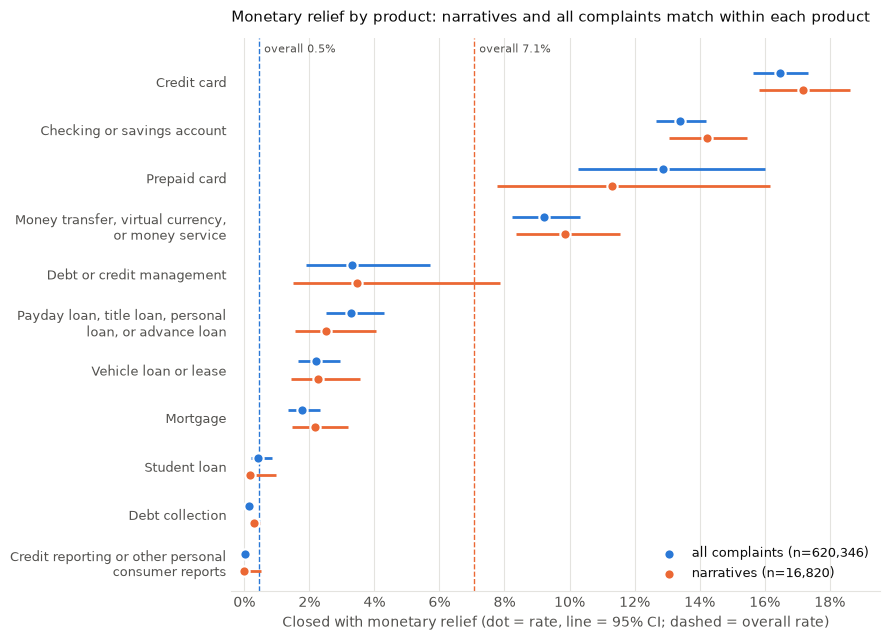

In [9]:
# --- Chart: monetary relief by product -------------------------------------
# Colors: categorical slots 1-2 of a palette validated for colorblind separation
POP_COLORS = {"all complaints": "#2a78d6", "narratives": "#eb6834"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DODGE = 0.18  # vertical offset within a row so the two CIs don't overlap


def relief_points(df, outcome):
    """Rate of one outcome and its 95% Wilson CI (in %) per product; 'In progress' excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    is_outcome = closed[OUTCOME_COL].eq(outcome).groupby(closed["Product"])
    k, n = is_outcome.sum(), is_outcome.size()
    low, high = wilson_ci(k, n)
    return pd.DataFrame({"n": n, "k": k, "rate": 100 * k / n, "low": 100 * low, "high": 100 * high})


def plot_relief_dots(points, xlabel, title, tick_step):
    """Dot plot per product, one dot + CI per population, sorted by the all-complaints rate (highest on top)."""
    order = points["all complaints"].sort_values("rate").index
    y = np.arange(len(order))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    for offset, (name, pts) in zip([DODGE, -DODGE], points.items()):
        pts = pts.reindex(order)
        color = POP_COLORS[name]
        overall = 100 * pts["k"].sum() / pts["n"].sum()
        ax.axvline(overall, color=color, lw=1, ls="--", zorder=1)
        ax.text(overall + 0.15, len(order) - 0.45, f"overall {overall:.1f}%", color=INK_MUTED, fontsize=8, va="bottom")
        ax.hlines(y + offset, pts["low"], pts["high"], color=color, lw=2, zorder=2)
        ax.scatter(pts["rate"], y + offset, s=55, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{name} (n={pts['n'].sum():,})")

    ax.set_yticks(y, [textwrap.fill(p, 34) for p in order], fontsize=9, color=INK)
    ax.set_ylim(-0.6, len(order) - 0.1)
    ax.set_xlim(-0.4, None)  # just below 0 so dots at 0% aren't clipped
    ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(tick_step))
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel(f"{xlabel} (dot = rate, line = 95% CI; dashed = overall rate)", color=INK_MUTED)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=12)
    fig.tight_layout()
    plt.show()


monetary_points = {name: relief_points(df_pop, MONETARY) for name, df_pop in populations.items()}

# Checks: the plotted numbers must match relief_table(), and each dot must sit inside its CI
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = monetary_points[name].reindex(expected.index)
    rate_diff = (pts["rate"].round(1) - expected["monetary_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: rate per product matches relief_table", rate_diff == 0,
              f"(max abs difference {rate_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

plot_relief_dots(monetary_points, xlabel="Closed with monetary relief", tick_step=2,
                 title="Monetary relief by product: narratives and all complaints match within each product")

**Reading the chart**

- **Unit.** Each percentage is a share of complaints: of the closed complaints in that group, how many ended "Closed with monetary relief". It counts complaints, not dollars (the export has no amounts). "In progress" complaints are excluded; "Untimely response" counts as closed without relief.
- **Within a product (dots).** Each row uses only that product's own complaints as the base. Example: 488 of 2,840 credit-card narratives (17.2%) got monetary relief, vs. 16.5% of all 7,380 closed credit-card complaints.
- **Across products (dashed lines).** Each dashed line pools all of a population's complaints: 0.5% for all complaints (2,855 of 620,346) and 7.1% for narratives (1,190 of 16,820). This is a weighted average of the dots, weighted by how many complaints each product has, not a simple average of the 11 dots.
- **Confidence intervals.** Each line is the 95% Wilson CI, the plausible range for the rate given its sample size. Large groups give short lines (credit card, all complaints: 15.6-17.3%); small groups give long ones (prepaid card, narratives, n=221: 7.8-16.2%). When the two lines in a row overlap, the data cannot tell the two populations apart.
- **Percentage points.** Gaps between rates are in percentage points: credit card (16.5%) vs. mortgage (1.8%) is a 14.7-point gap, about 9 times higher in relative terms, not "14.7% higher".

**What it shows**

1. **Product drives the rate.** Credit card, checking/savings, prepaid card and money transfer sit at about 9-17%; every other product is under 4%, and credit reporting is about 0%.
2. **Within each product, narratives match all complaints.** In every row the blue and orange CIs overlap. Debt collection overlaps only narrowly (0.15% vs. 0.29%), a gap of about 0.1 points at a very low rate.
3. **The overall gap (0.5% vs. 7.1%) comes from product mix, not from the narrative.** Credit reporting (about 0%) is 91.2% of all closed complaints but only 4.5% of narratives. The four high-relief products are 3.0% of all complaints but 45.6% of narratives. Comparing the dashed lines alone would wrongly suggest narratives are about 14 times more likely to get monetary relief.

**Limits.** These are associations, not causes: a high rate says which complaints tend to end in monetary relief, not why. The chart also says nothing about relief amounts. For the report, quote narrative relief rates per product, or state that the overall 7.1% reflects the product mix.

#### Chart: Non-Monetary Relief by Product

Same layout as the monetary chart, for `Closed with non-monetary relief`. Each complaint has one closure category, so for every product monetary + non-monetary = any relief; the cell checks that against `relief_table()` before plotting, and lists the products where the two populations' CIs do not overlap.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  

CIs that don't overlap (2 of 11 products):
  Credit reporting or other personal consumer reports: all 36.5% (36.4-36.6) vs. narratives 40.9% (37.4-44.4)
  Debt collection: all 26.3% (25.8-26.9) vs. narratives 24.3% (23.2-25.5)


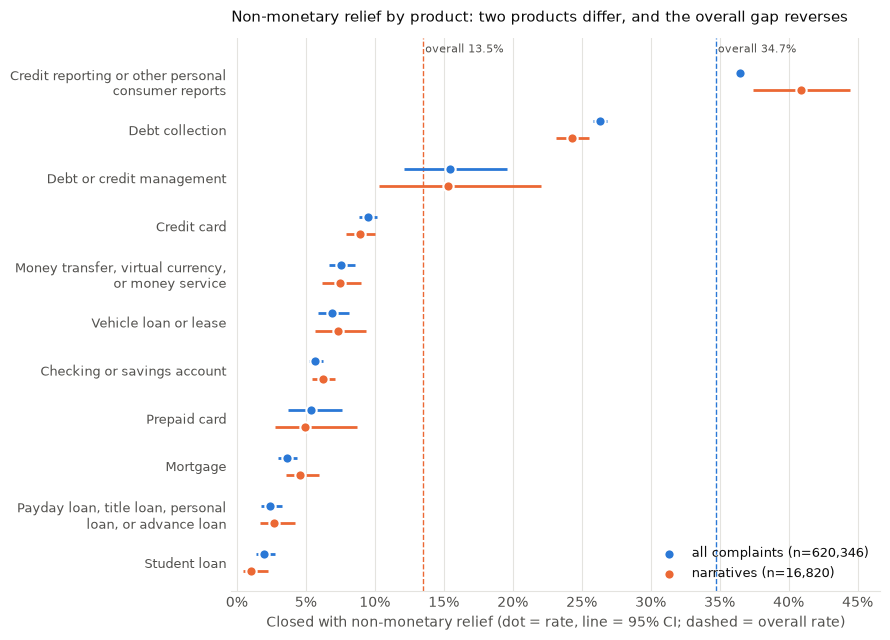

In [10]:
# --- Chart: non-monetary relief by product ---------------------------------
non_monetary_points = {name: relief_points(df_pop, NON_MONETARY) for name, df_pop in populations.items()}

# Checks: n matches relief_table(); monetary + non-monetary counts reproduce its any-relief rate
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = non_monetary_points[name].reindex(expected.index)
    any_k = pts["k"] + monetary_points[name].reindex(expected.index)["k"]
    any_diff = ((100 * any_k / pts["n"]).round(1) - expected["any_relief_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: monetary + non-monetary = any relief", any_diff == 0,
              f"(max abs difference {any_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# Products where the two populations' CIs don't overlap
all_pts = non_monetary_points["all complaints"]
nar_pts = non_monetary_points["narratives"].reindex(all_pts.index)
no_overlap = (nar_pts["low"] > all_pts["high"]) | (nar_pts["high"] < all_pts["low"])
print(f"\nCIs that don't overlap ({no_overlap.sum()} of {len(no_overlap)} products):")
for product in all_pts.index[no_overlap]:
    a, b = all_pts.loc[product], nar_pts.loc[product]
    print(f"  {product}: all {a['rate']:.1f}% ({a['low']:.1f}-{a['high']:.1f}) "
          f"vs. narratives {b['rate']:.1f}% ({b['low']:.1f}-{b['high']:.1f})")

plot_relief_dots(non_monetary_points, xlabel="Closed with non-monetary relief", tick_step=5,
                 title="Non-monetary relief by product: two products differ, and the overall gap reverses")

**Reading the chart**

Read it like the monetary chart above (same unit, CIs and percentage points). Non-monetary relief means the company reported a concrete, non-cash fix, such as correcting a credit report or stopping collection calls (CFPB definition quoted under Relief Patterns). Because each complaint has one closure category, a product's monetary rate (chart above) plus its non-monetary rate (this chart) is its any-relief rate.

**What it shows**

1. **The overall gap reverses.** Narratives have the *lower* overall rate here: 13.5% (2,272 of 16,820) vs. 34.7% (215,435 of 620,346) for all complaints, the opposite of the monetary chart (7.1% vs. 0.5%). The cause is the same product mix: credit reporting has the highest non-monetary rate and is 91.2% of all closed complaints but only 4.5% of narratives.
2. **Two products differ within the product** (their CIs don't overlap):
   - *Credit reporting*: narratives higher, 40.9% (37.4-44.4) vs. 36.5% (36.4-36.6), a 4.4-point gap.
   - *Debt collection*: narratives lower, 24.3% (23.2-25.5) vs. 26.3% (25.8-26.9), a 2.0-point gap.
3. **The other nine products match**, as in the monetary chart.

**Limits.** The data shows that these two gaps exist, not why. The narrative itself, the kind of issue people write about, or how companies respond to written complaints could each play a part; nothing here separates them. As before, the categories are company-reported, and the rates are associations, not causes.

**Implication for the narrative subset.** For both relief types, most of the difference between narratives and all complaints comes from product mix. Within products, narratives mostly look like all complaints, with two exceptions worth keeping in mind: credit reporting and debt collection.

## Clean

All cleaning lives in one function, `clean_ccdb()`, so it runs as a single pipeline and can be reapplied to another export (e.g. March 2026).
- `df_raw` is never modified; the function returns `df_clean` plus a cleaning log (one row per step).
- Steps marked `PENDING` are placeholders for decisions not made yet (several depend on the use case).
- Category conversion runs last, after all recoding, and never touches the narrative.

In [11]:
# --- Cleaning pipeline -----------------------------------------------------
DATE_COLS = ["Date received", "Date sent to company"]
CATEGORY_COLS = [
    "Product", "Sub-product", "Issue", "Sub-issue", "Company public response",
    "Company", "State", "Submitted via", "Company response to consumer",
]
TIMELY_MAP = {"Yes": True, "No": False}


def clean_ccdb(raw):
    """Clean a raw CCDB export read with dtype=str.

    Returns (cleaned DataFrame, cleaning log). The input is not modified.
    """
    df = raw.copy()
    log = []

    def record(step, detail, rows_affected):
        log.append({"step": step, "detail": detail, "rows_affected": int(rows_affected)})

    # 1. Whitespace: strip every text column; blanks left after stripping become missing
    stripped_rows = pd.Series(False, index=df.index)
    emptied_rows = pd.Series(False, index=df.index)
    for col in df.columns:
        stripped = df[col].str.strip()
        stripped_rows |= (stripped != df[col]) & df[col].notna()  # missing != missing is True, so exclude it
        emptied = stripped.eq("").fillna(False)
        emptied_rows |= emptied
        df[col] = stripped.mask(emptied)
    record("Whitespace", "Leading/trailing spaces stripped in all columns", stripped_rows.sum())
    record("Empty strings", "Blank values after stripping set to missing", emptied_rows.sum())

    # 2. Dates: YYYY-MM-DD text to datetime; stop if any value doesn't parse
    for col in DATE_COLS:
        parsed = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
        unparsed = parsed.isna() & df[col].notna()
        assert not unparsed.any(), f"{col}: {unparsed.sum():,} values not in YYYY-MM-DD format"
        df[col] = parsed
        record("Dates", f"{col} converted to datetime", df[col].notna().sum())

    # 3. Hidden missing values
    masked_zip = df["ZIP code"].eq("XXXXX").fillna(False)
    df.loc[masked_zip, "ZIP code"] = np.nan
    record("ZIP code", "'XXXXX' set to missing", masked_zip.sum())
    # Sub-product 'I do not know' is kept as its own value (decided 2026-10-26):
    # it records that the consumer could not classify the complaint, not missing data.

    # 4. Tags: split the combined text into two yes/no flags, then drop the original
    tags = df["Tags"].fillna("")
    unknown_tags = set(tags.str.split(", ").explode()) - {"", "Older American", "Servicemember"}
    assert not unknown_tags, f"Unexpected Tags values: {unknown_tags}"
    df["Older American"] = tags.str.contains("Older American", regex=False)
    df["Servicemember"] = tags.str.contains("Servicemember", regex=False)
    df = df.drop(columns="Tags")
    record("Tags", "Split into Older American / Servicemember flags; Tags dropped",
           (df["Older American"] | df["Servicemember"]).sum())

    # 5. Timely response?: Yes/No to boolean; stop on any other value
    unmapped = set(df["Timely response?"].dropna()) - set(TIMELY_MAP)
    assert not unmapped, f"Unexpected Timely response? values: {unmapped}"
    df["Timely response?"] = df["Timely response?"].map(TIMELY_MAP).astype("boolean")
    record("Timely response?", "Yes/No converted to boolean", df["Timely response?"].notna().sum())

    # 6. PENDING: Company public response - recode after reading the full text of the 62.2% value
    # 7. PENDING: State - review the codes beyond the 50 states + DC
    # 8. PENDING (use case): narrative subset, duplicate narratives, outcome label, text length

    # 9. Categories (always last, after all recoding; the narrative stays text)
    for col in CATEGORY_COLS:
        df[col] = df[col].astype("category")
    record("Categories", f"{len(CATEGORY_COLS)} label columns converted to category", len(df))

    return df, pd.DataFrame(log)

In [12]:
# --- Run cleaning + checks -------------------------------------------------
df_clean, cleaning_log = clean_ccdb(df_raw)
display(cleaning_log)

received = df_clean["Date received"]
sent_before_received = (df_clean["Date sent to company"] < received).sum()

results = [
    check("Row count unchanged", len(df_clean) == len(df_raw), f"({len(df_clean):,} rows)"),
    check("Complaint ID still unique", df_clean["Complaint ID"].is_unique),
    check("Date received within June 2026",
          received.between("2026-06-01", "2026-06-30").all(),
          f"({received.min():%Y-%m-%d} to {received.max():%Y-%m-%d})"),
    check("Date sent on or after Date received", sent_before_received == 0,
          f"({sent_before_received:,} violations; sent range "
          f"{df_clean['Date sent to company'].min():%Y-%m-%d} to {df_clean['Date sent to company'].max():%Y-%m-%d})"),
    check("df_raw untouched", list(df_raw.columns) == EXPECTED_COLS
          and not pd.api.types.is_datetime64_any_dtype(df_raw["Date received"])),
]
assert all(results), "A cleaning check failed; see the FAIL lines above"

raw_mb = df_raw.memory_usage(deep=True).sum() / 1e6
clean_mb = df_clean.memory_usage(deep=True).sum() / 1e6
print(f"\nMemory: {raw_mb:,.0f} MB raw -> {clean_mb:,.0f} MB clean")

,step,detail,rows_affected
0,Whitespace,Leading/trailing spaces stripped in all columns,0
1,Empty strings,Blank values after stripping set to missing,0
2,Dates,Date received converted to datetime,620794
3,Dates,Date sent to company converted to datetime,620794
4,ZIP code,'XXXXX' set to missing,1694
5,Tags,Split into Older American / Servicemember flags; Tags dropped,13853
6,Timely response?,Yes/No converted to boolean,620794
7,Categories,9 label columns converted to category,620794


PASS  Row count unchanged  (620,794 rows)
PASS  Complaint ID still unique  
PASS  Date received within June 2026  (2026-06-01 to 2026-06-30)
PASS  Date sent on or after Date received  (0 violations; sent range 2026-06-01 to 2026-09-09)
PASS  df_raw untouched  

Memory: 670 MB raw -> 133 MB clean


### Schema Check and Data Dictionary Export

PENDING: once cleaning decisions are final, assert the expected dtype of every column in `df_clean` (PASS/FAIL), then write the column / role / dtype / null_% / CFPB description table between the markers in `data/README.md`.